# <center> Regional Solar Energy Potential Analysis</center>

## Visualizing Solar Irradiance Data

Shenzhen: 52560 records from 2020-01-01 00:00:00 to 2020-12-31 23:50:00


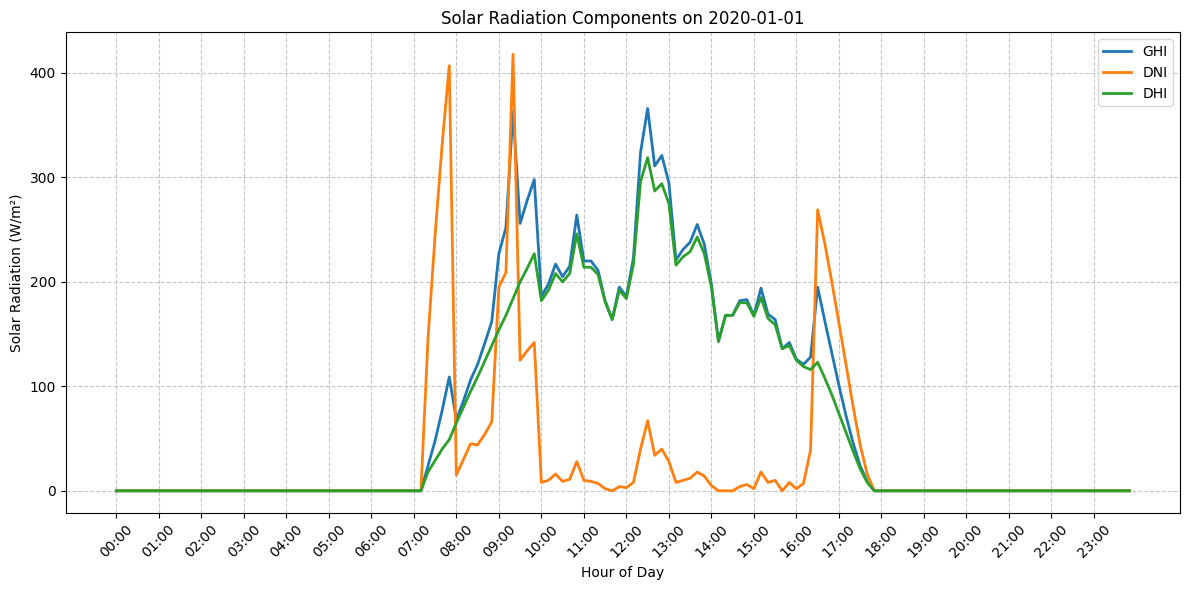

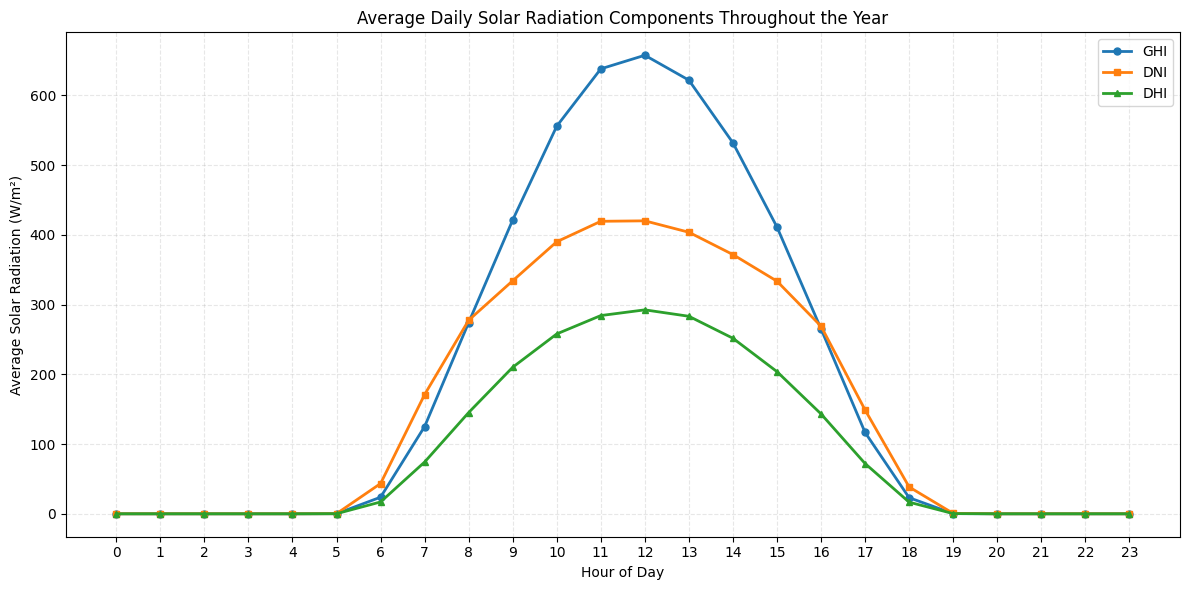

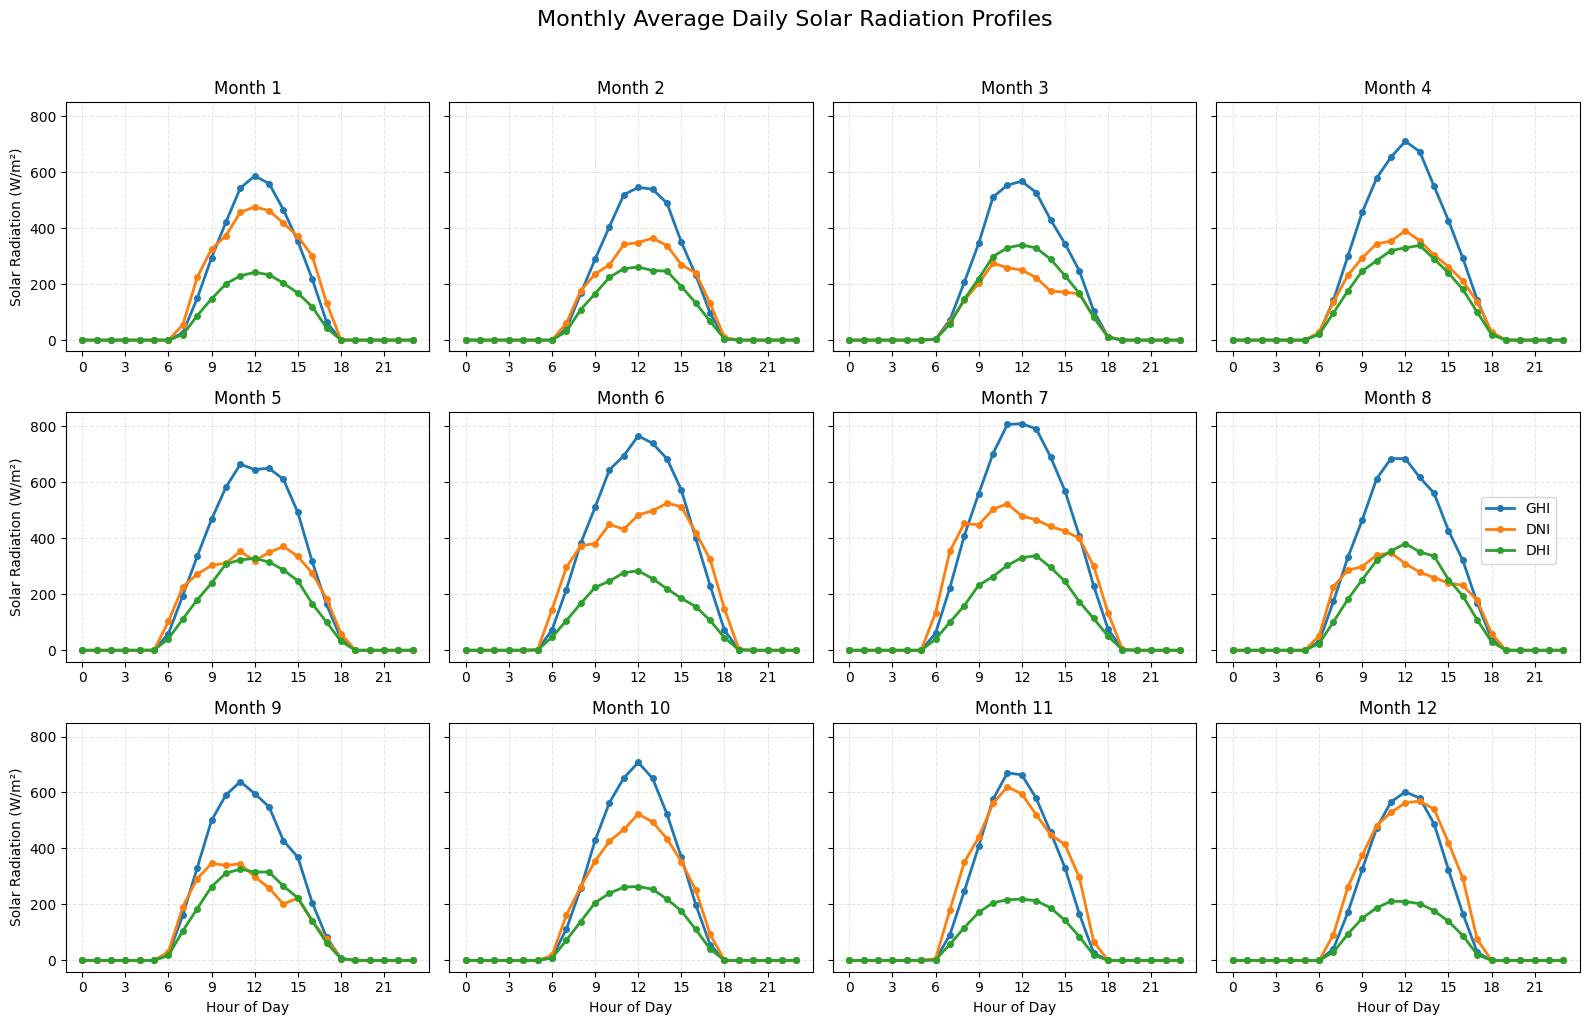

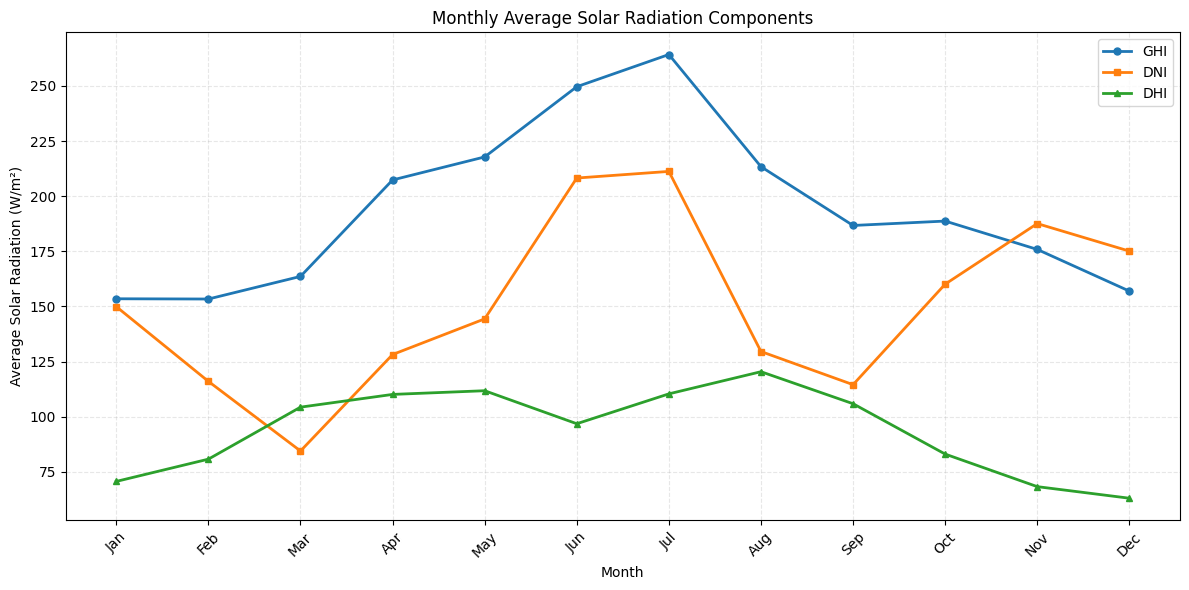

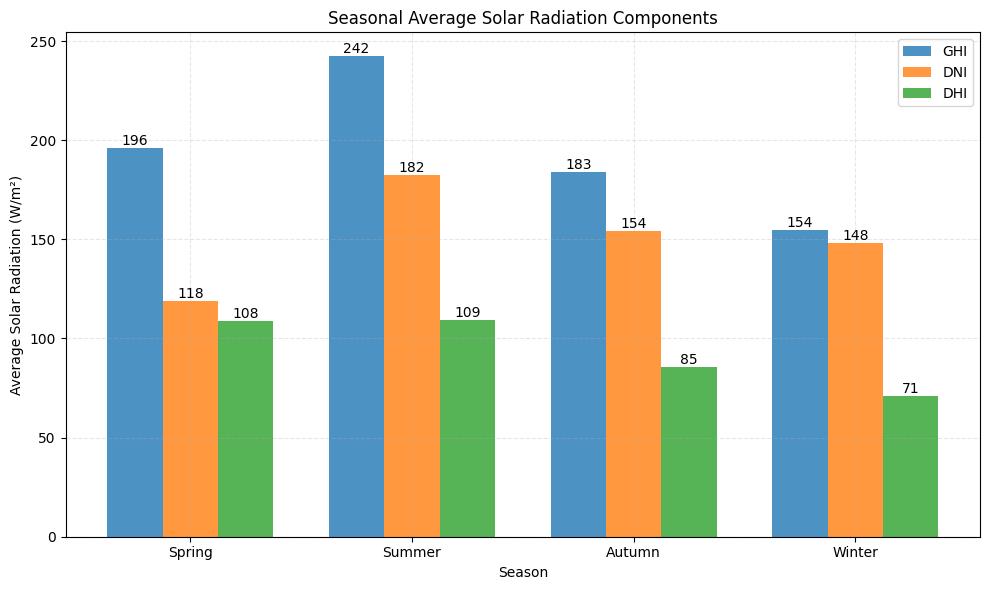

In [3]:
import weather_visualization as swv
import matplotlib.pyplot as plt
import os
%matplotlib inline

# Choose your city: 'Bangkok', 'Seoul', 'Shenzhen' or 'Tokyo'
city_name = 'Shenzhen'

# Load weather data (10-minute resolution, local standard time)
weather = swv.read_weather(os.path.join('./weather_data', f'{city_name}_weather.csv'))

# Read the year from the data itself (e.g. the Shenzhen file is 2020, the others are 2019)
year = weather.index.year[0]
print(f'{city_name}: {len(weather)} records from {weather.index[0]} to {weather.index[-1]}')

# Visualize data for a specific day
# Here, we use the first day in the dataset as an example, but you can modify it to other dates
first_date = f'{year}-01-01'
swv.plot_single_day(weather, first_date)
plt.show()

# Visualize the average daily profile over the entire year
swv.plot_daily_avg(weather)
plt.show()

# Visualize the average daily profile for each month (12 subplots)
swv.plot_monthly_avg(weather)
plt.show()

# Visualize the monthly average radiation (night-time zeros included)
swv.plot_monthly_hourly(weather)
plt.show()

# Visualize seasonal data
swv.plot_seasonal(weather)
plt.show()

## POA Calculation and Visualization

Representative location: latitude 22.7748, longitude 113.8369
Annual POA irradiation - fixed: 1796 kWh/m², tracked: 2283 kWh/m²


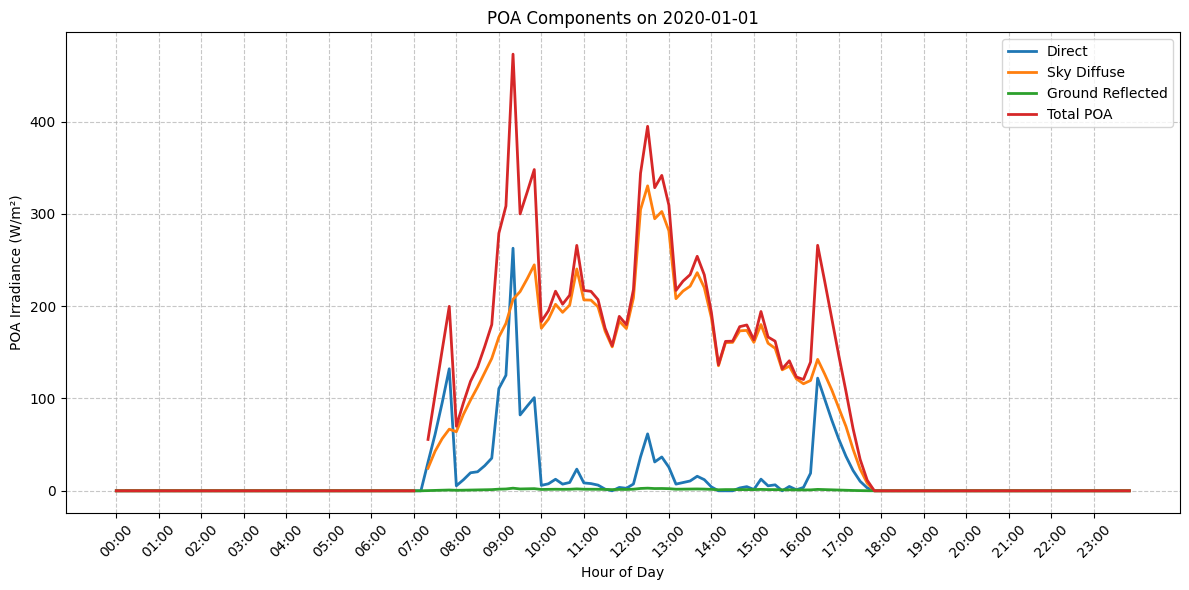

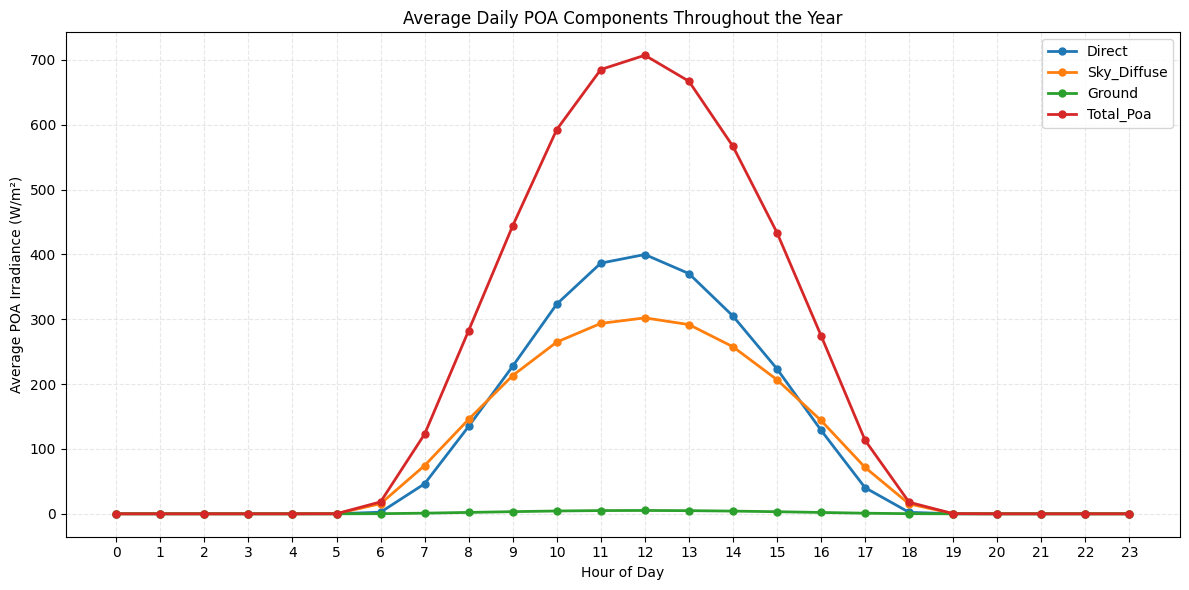

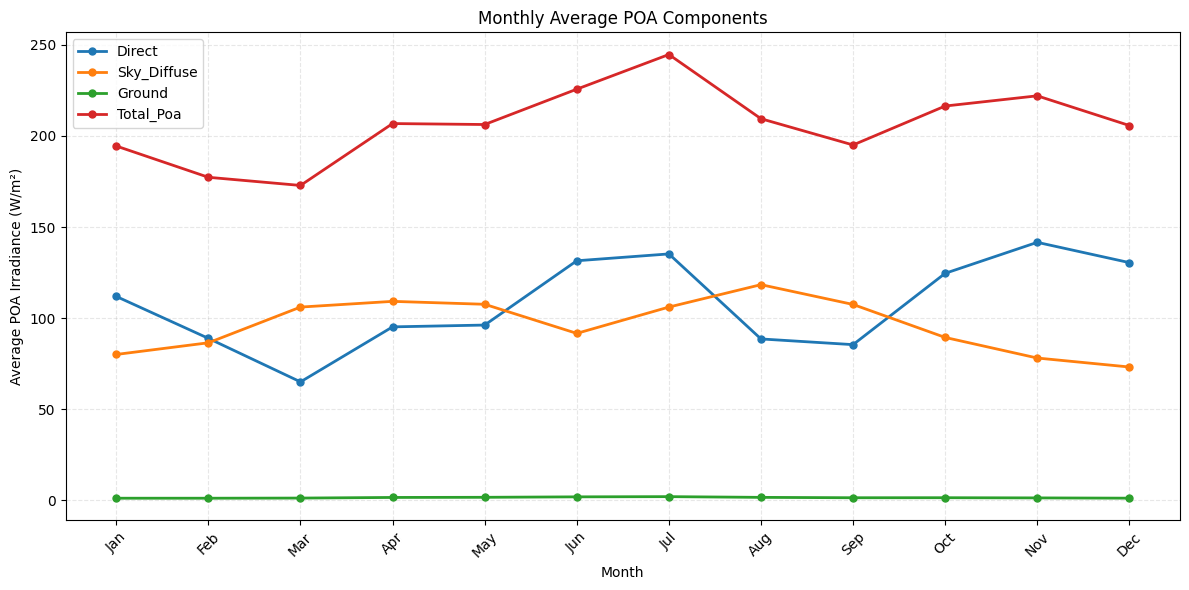

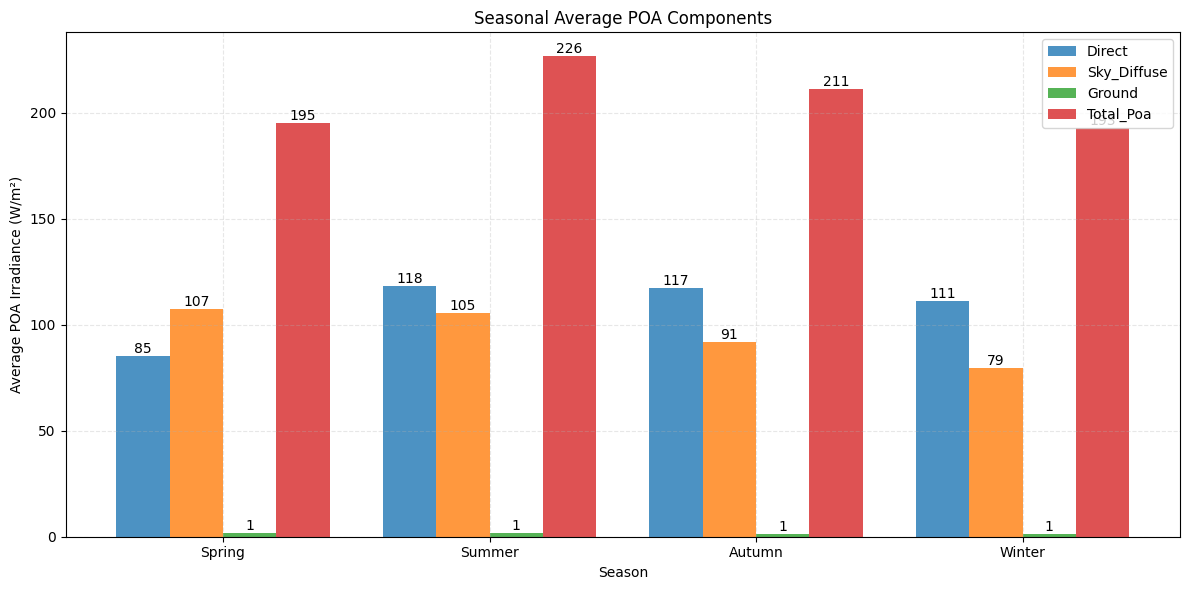

In [4]:
from poa_calculation import calculate_poa, calculate_poa_track
from poa_visualization import *
import geopandas as gpd
import pandas as pd

# Load building data for the selected city
buildings = gpd.read_file(os.path.join('./buildings_data', f'{city_name}_building.geojson'))

# Calculate the mean latitude and longitude of the buildings' centroids
# This is done to get a representative location for the POA calculation.
# Centroids are computed in a projected (UTM) CRS and converted back to lon/lat
centroids = buildings.to_crs(buildings.estimate_utm_crs()).geometry.centroid.to_crs(epsg=4326)
latitude = centroids.y.mean()
longitude = centroids.x.mean()
print(f'Representative location: latitude {latitude:.4f}, longitude {longitude:.4f}')

# Determine the surface azimuth based on the latitude
# For locations north of the equator, the surface azimuth is set to 180 degrees (facing south)
# For locations south of the equator, the surface azimuth is set to 0 degrees (facing north)
if latitude > 0:
    surface_azimuth = 180
else:
    surface_azimuth = 0

# Fixed system: tilt angle = |latitude| (a common rule of thumb for annual yield)
surface_tilt = abs(latitude)

# Calculate the Plane of Array (POA) irradiance for a fixed system
poa_fixed = calculate_poa(weather, surface_tilt, surface_azimuth, latitude, longitude)

# Calculate the POA irradiance for a dual-axis tracking system
poa_track = calculate_poa_track(weather, latitude, longitude)

# Convert the calculated POA data into DataFrames for easier manipulation
poa_df_fixed = pd.DataFrame(poa_fixed)
poa_df_tracked = pd.DataFrame(poa_track)

# Annual POA irradiation (10-minute data: W/m² x 1/6 h = Wh/m²)
print(f"Annual POA irradiation - fixed: {poa_df_fixed['total_poa'].sum() / 6 / 1000:.0f} kWh/m², "
      f"tracked: {poa_df_tracked['total_poa'].sum() / 6 / 1000:.0f} kWh/m²")

# Save the POA data for both fixed and tracked systems to CSV files
poa_df_fixed.to_csv(os.path.join('./result', f'{city_name}_poa_fixed_results.csv'), index=False)
poa_df_tracked.to_csv(os.path.join('./result', f'{city_name}_poa_tracked_results.csv'), index=False)

# Visualize the POA components for a specific day (January 1st)
plot_poa_single_day(poa_df_fixed, f'{year}-01-01')
plt.show()

# Visualize the annual average daily POA change
plot_poa_daily_avg(poa_df_fixed)
plt.show()

# Visualize the monthly POA change
plot_poa_monthly_avg(poa_df_fixed)
plt.show()

# Visualize the seasonal POA change
plot_poa_seasonal(poa_df_fixed)
plt.show()

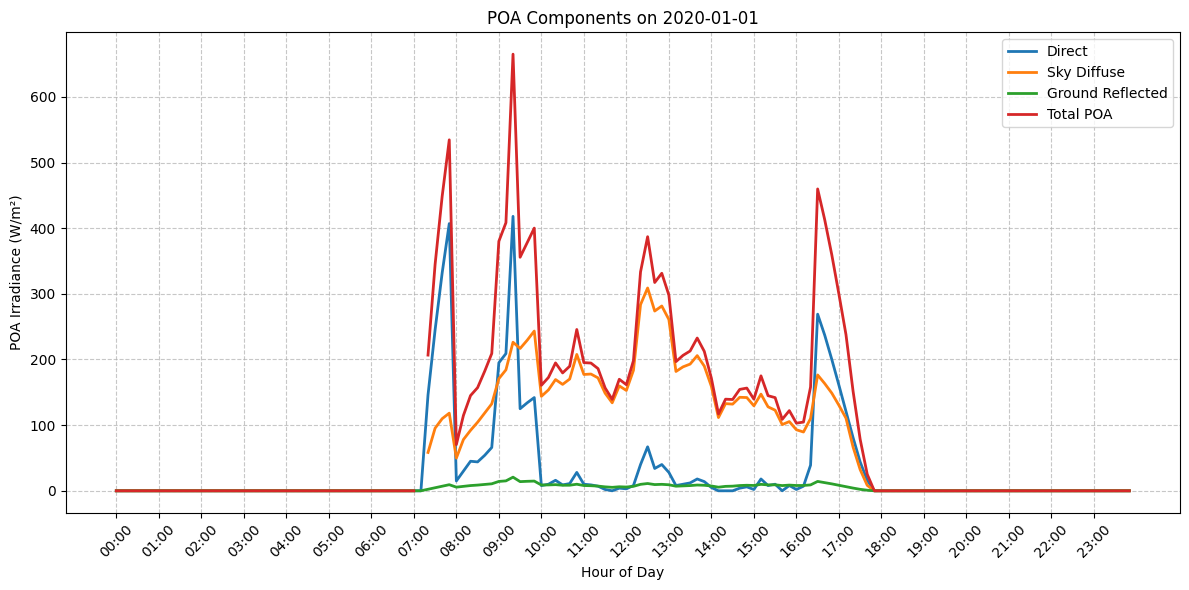

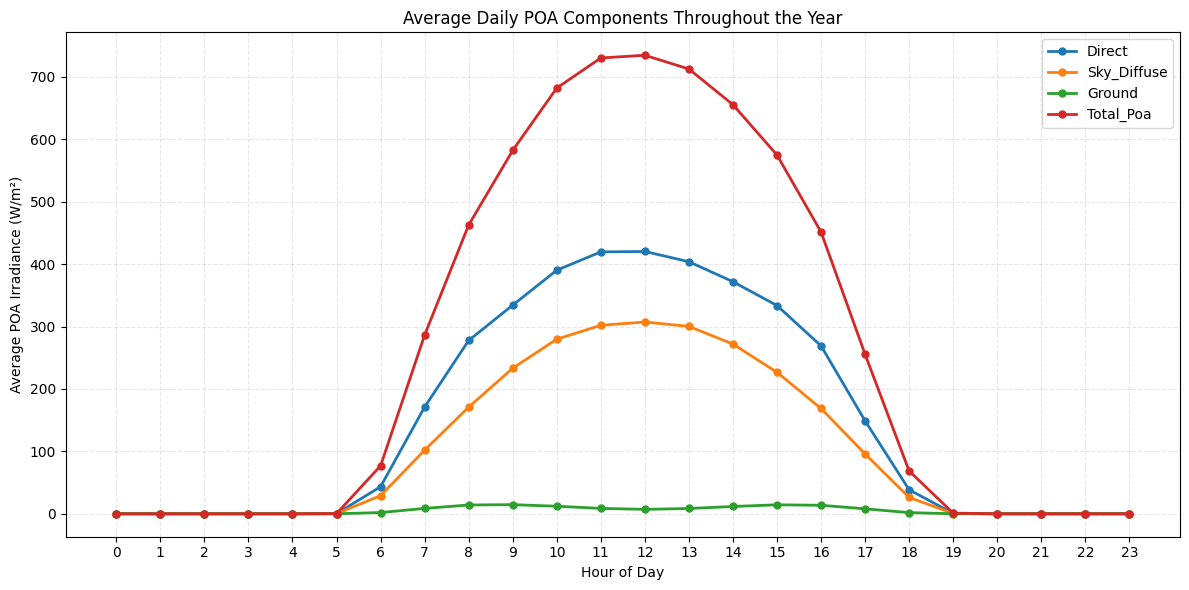

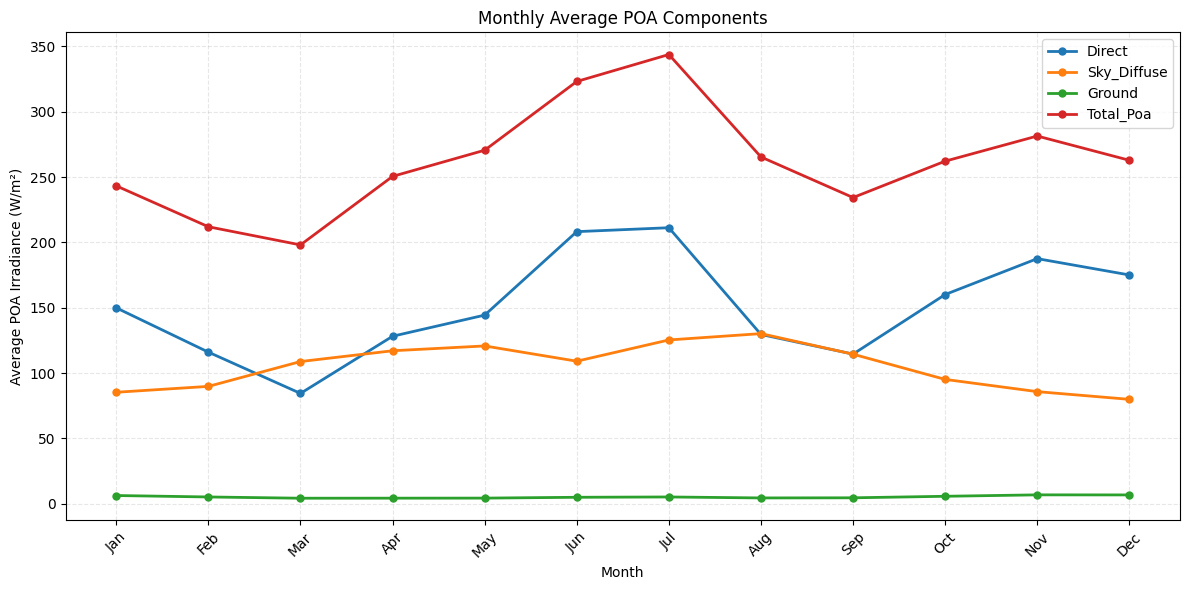

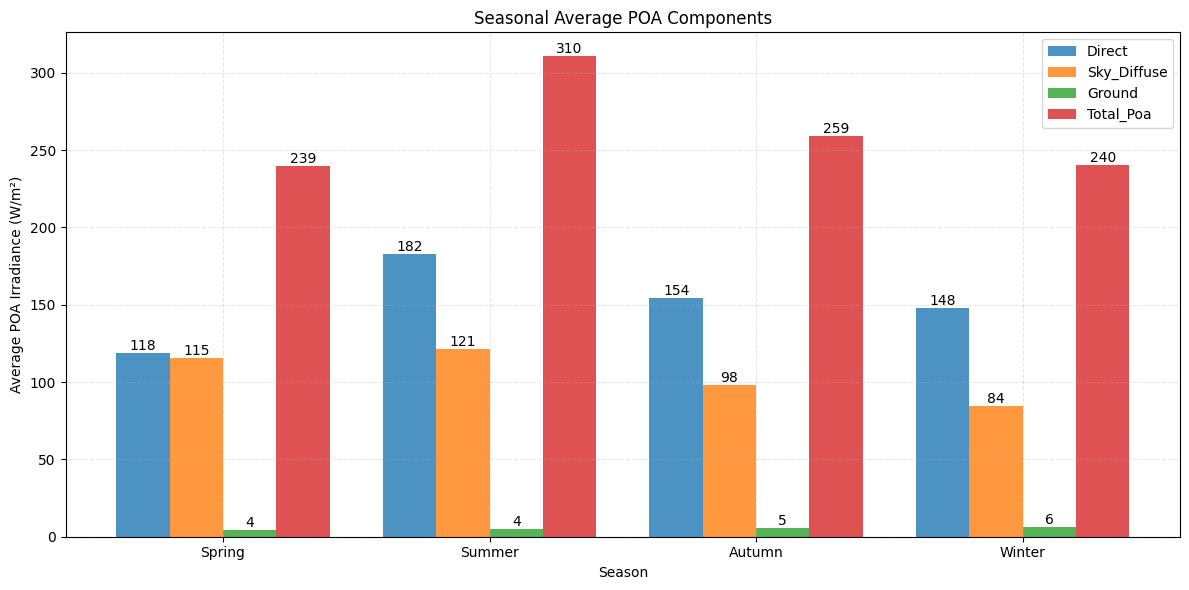

In [5]:
# Plotting the POA for a single day for the tracked system
plot_poa_single_day(poa_df_tracked, f'{year}-01-01')
plt.show()

# Plotting the annual average daily POA change for the tracked system
plot_poa_daily_avg(poa_df_tracked)
plt.show()

# Plotting the monthly POA change for the tracked system
plot_poa_monthly_avg(poa_df_tracked)
plt.show()

# Plotting the seasonal POA change for the tracked system
plot_poa_seasonal(poa_df_tracked)
plt.show()

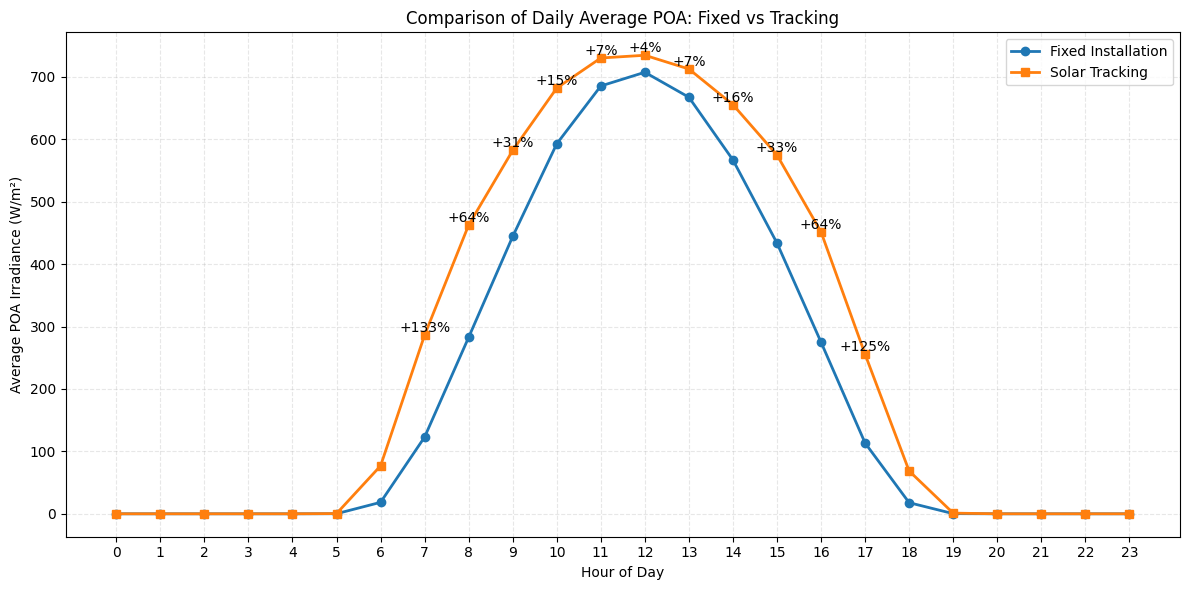

In [6]:
# Importing the function to compare daily POA for fixed and tracked systems
from poa_visualization import compare_fixed_tracked_daily
# Calling the function to compare daily POA for fixed and tracked systems
compare_fixed_tracked_daily(poa_df_fixed, poa_df_tracked)
plt.show()

## PV Output Calculation and Visualization

The output is the DC power of **one PV module** (W), computed with the PVsyst single-diode model and the SAPM cell-temperature model. Optical (incidence angle), soiling, wiring and inverter losses are not included.

In [7]:
# Importing the function to calculate PV efficiency with rounding
from Efficiency_calculation import calculate_pv_efficiency_round

# Area of one PV module (m²); also used later for the rooftop calculation
module_area = 1.69

# Defining the module parameters for the PVsyst single-diode model
module_parameters = {
    'gamma_ref': 1,  # Diode ideality factor at reference conditions
    'mu_gamma': 0.002,  # Temperature coefficient of the diode ideality factor (1/K)
    'I_L_ref': 7.3,  # Light-generated current at reference conditions (A)
    'I_o_ref': 1e-10,  # Diode reverse saturation current at reference conditions (A)
    'R_sh_ref': 400,  # Shunt resistance at reference irradiance (Ω)
    'R_s': 0.3,  # Series resistance (Ω)
    'R_sh_0': 3000,  # Shunt resistance at zero irradiance (Ω)
    'cells_in_series': 60,  # Number of cells in series
    'alpha_sc': 0.004,  # Temperature coefficient of the short-circuit current (A/°C)
    'EgRef': 1.12,  # Bandgap energy at reference temperature (eV)
    'irrad_ref': 1000,  # Reference irradiance (W/m²)
    'temp_ref': 25  # Reference cell temperature (°C)
}

# Calculating the PV output for the fixed system
pvout_result_fixed = calculate_pv_efficiency_round(
    poa_data=poa_df_fixed,  # Plane of Array data for the fixed system
    weather_data=weather,  # Weather data
    module_area=module_area,  # Module area (m²)
    module_parameters=module_parameters  # Module parameters defined above
)

# Calculating the PV output for the tracked system
pvout_result_tracked = calculate_pv_efficiency_round(
    poa_data=poa_df_tracked,  # Plane of Array data for the tracked system
    weather_data=weather,  # Weather data
    module_area=module_area,  # Module area (m²)
    module_parameters=module_parameters  # Module parameters defined above
)

# Annual energy of one module (10-minute data: W x 1/6 h = Wh)
for name, result in [('Fixed', pvout_result_fixed), ('Tracked', pvout_result_tracked)]:
    annual_kwh = result['power'].sum() / 6 / 1000
    print(f'{name}: {annual_kwh:.0f} kWh per module per year = {annual_kwh / module_area:.0f} kWh/m² per year')

# Saving the results for the fixed system to a CSV file
pvout_result_fixed.to_csv(os.path.join('./result', f'{city_name}_efficiency_results.csv'), index=False)

# Saving the results for the tracked system to a CSV file
pvout_result_tracked.to_csv(os.path.join('./result', f'{city_name}_efficiency_results_tracked.csv'), index=False)

Fixed: 380 kWh per module per year = 225 kWh/m² per year
Tracked: 484 kWh per module per year = 286 kWh/m² per year


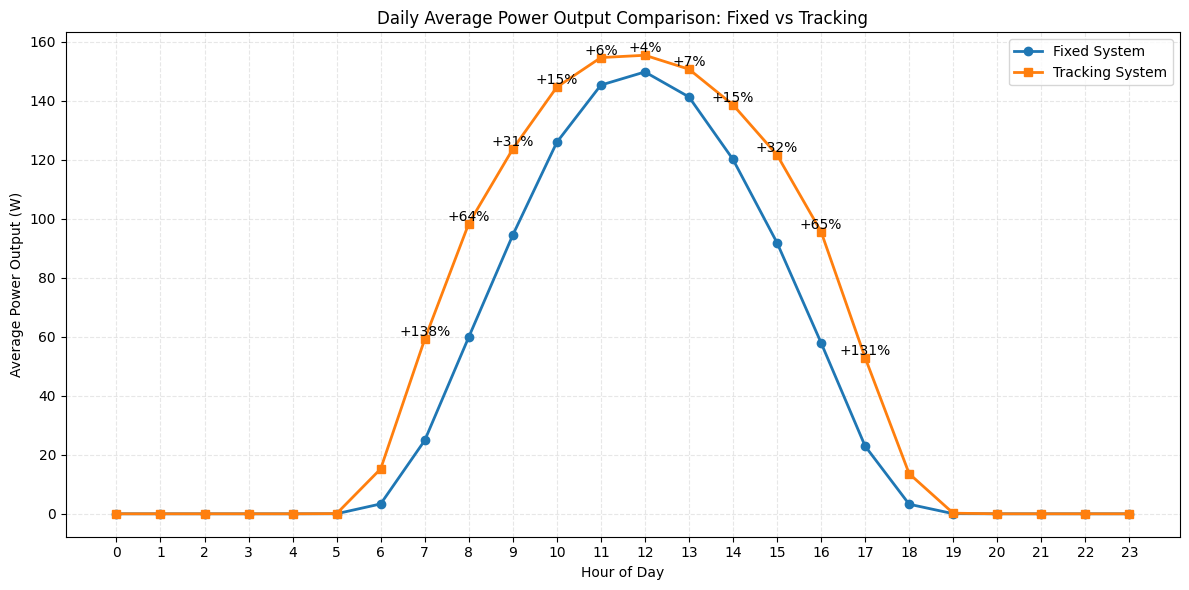

In [8]:
# Importing the function to plot daily PV power output
from poa_visualization import *
# Plotting the daily PV power output (per module) for both fixed and tracked systems
plot_pv_power_daily(pvout_result_fixed, pvout_result_tracked)
plt.show()

## Building Rooftop Solar Potential Assessment and Visualization

Annual energy of a building = usable roof area (m²) × annual yield per m² of PV module (kWh/m²). Roof areas are measured in a local UTM projection; Web Mercator (EPSG:3857) is used only for drawing the basemap.

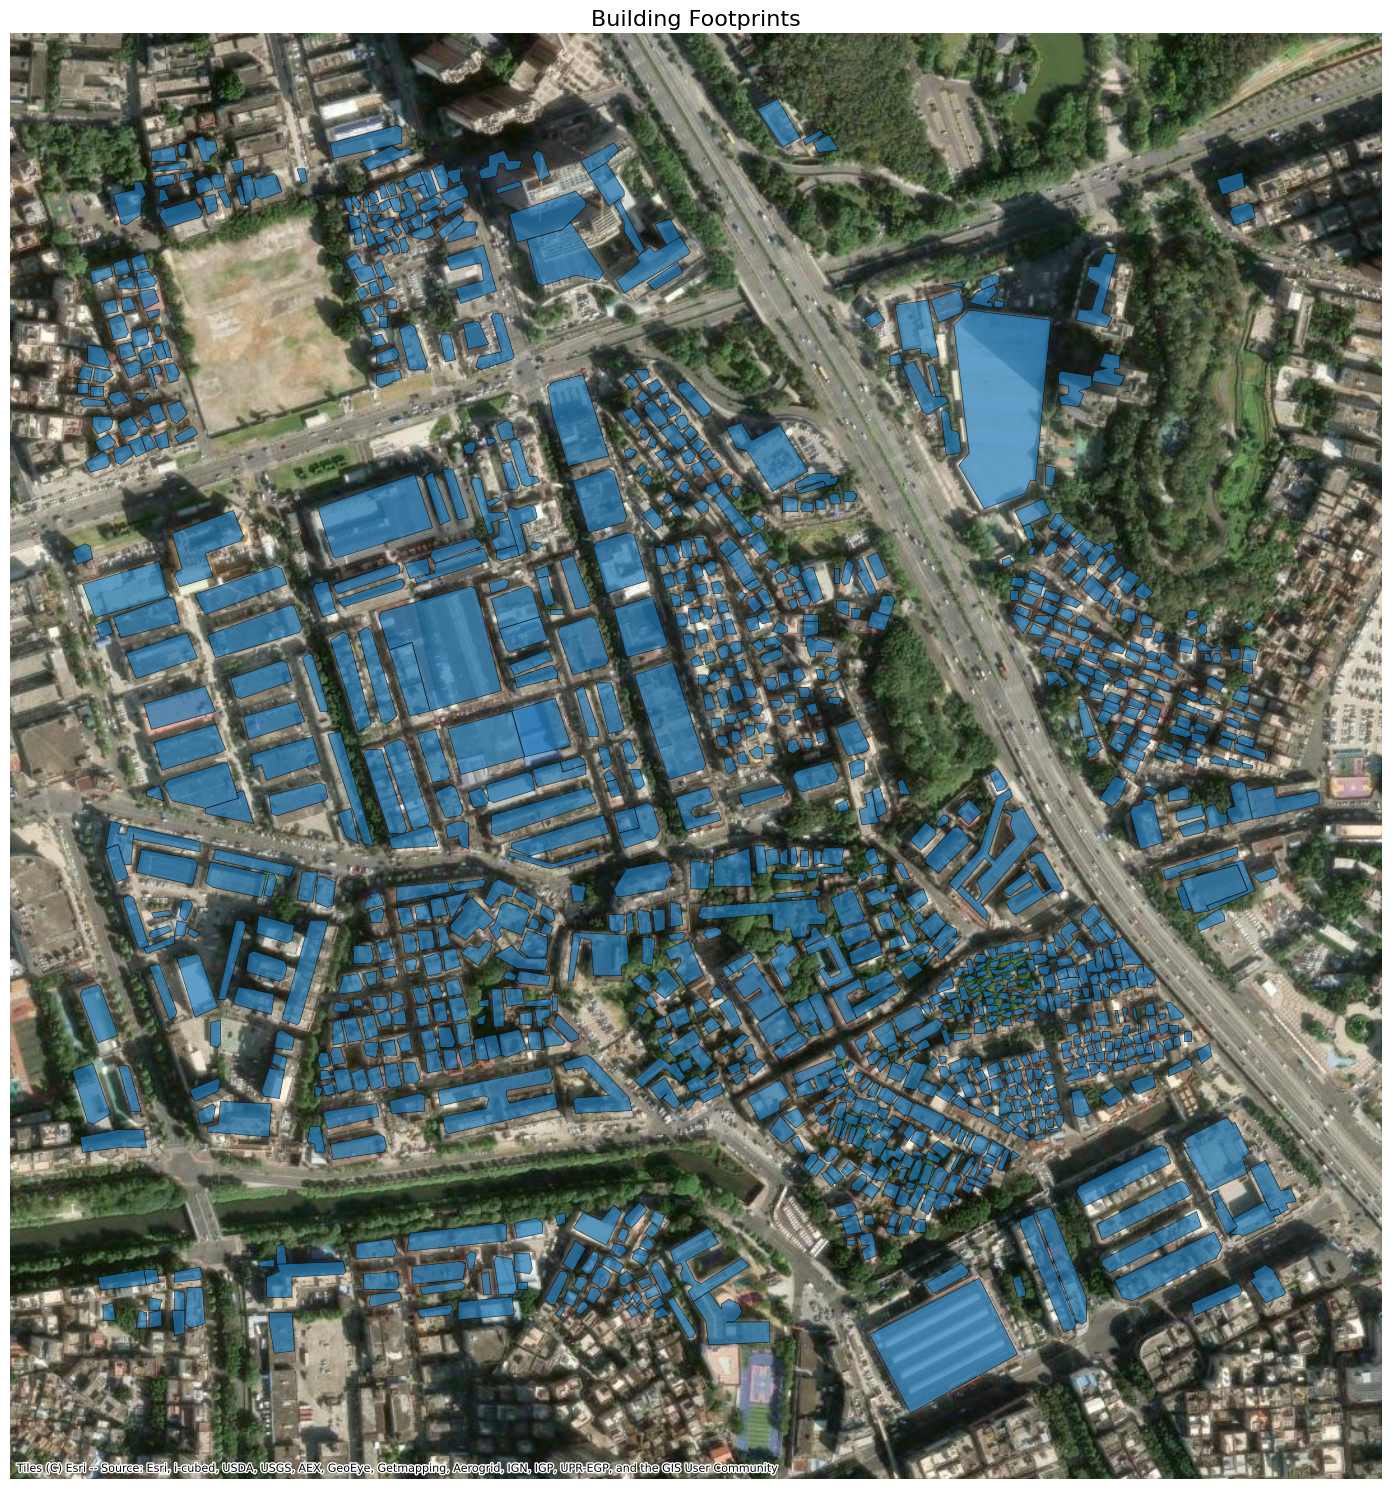

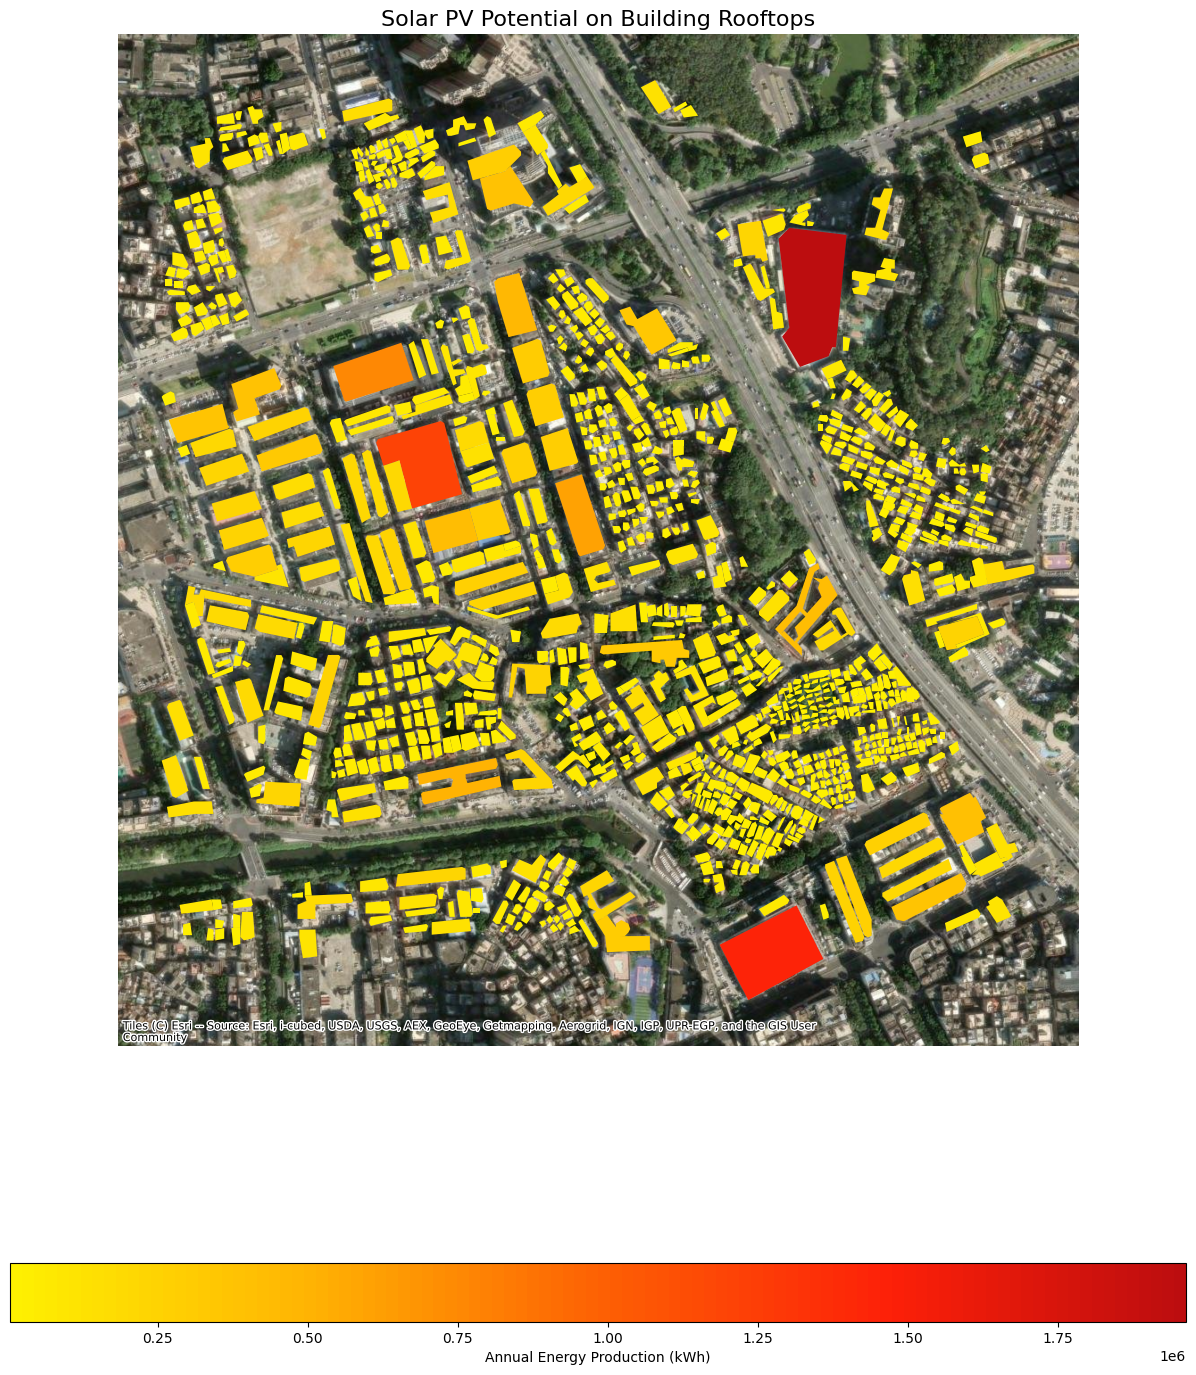

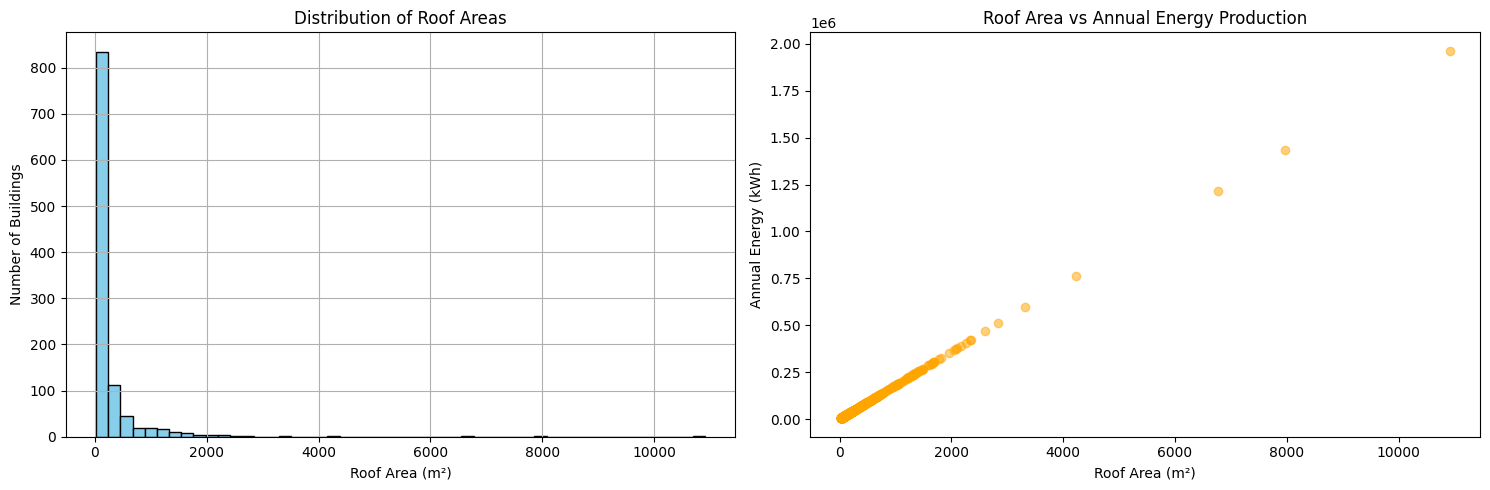

Solar PV Potential Summary - Shenzhen
Total number of buildings: 1080
Total roof area: 285,510 m²
Total annual energy production: 51,379 MWh
Average annual energy per building: 47,573 kWh


In [9]:
# Importing the necessary module for building PV potential analysis
from building_pv_potential import * 
# Importing pandas for data manipulation and analysis
import pandas as pd

# Defining the path to the GeoJSON file containing building data
geojson_path = os.path.join('./buildings_data', f'{city_name}_building.geojson')
# Visualizing the buildings using the provided GeoJSON path
buildings = visualize_buildings(geojson_path)

# Displaying the plot
plt.show()

# Calculating the PV potential for each building
# (assuming 80% of the roof area is usable for PV panels)
buildings = calculate_pv_potential(buildings, pvout_result_fixed,
                                   roof_efficiency=0.8, module_area=module_area)

# Visualizing the PV potential of each building
visualize_pv_potential(buildings)
# Displaying the plot
plt.show()

# Creating statistical charts for further analysis
create_statistics_plot(buildings)
plt.show()

# Summary statistics
print(f"Solar PV Potential Summary - {city_name}")
print(f"Total number of buildings: {len(buildings)}")
print(f"Total roof area: {buildings['roof_area'].sum():,.0f} m²")
print(f"Total annual energy production: {buildings['annual_energy'].sum() / 1000:,.0f} MWh")
print(f"Average annual energy per building: {buildings['annual_energy'].mean():,.0f} kWh")

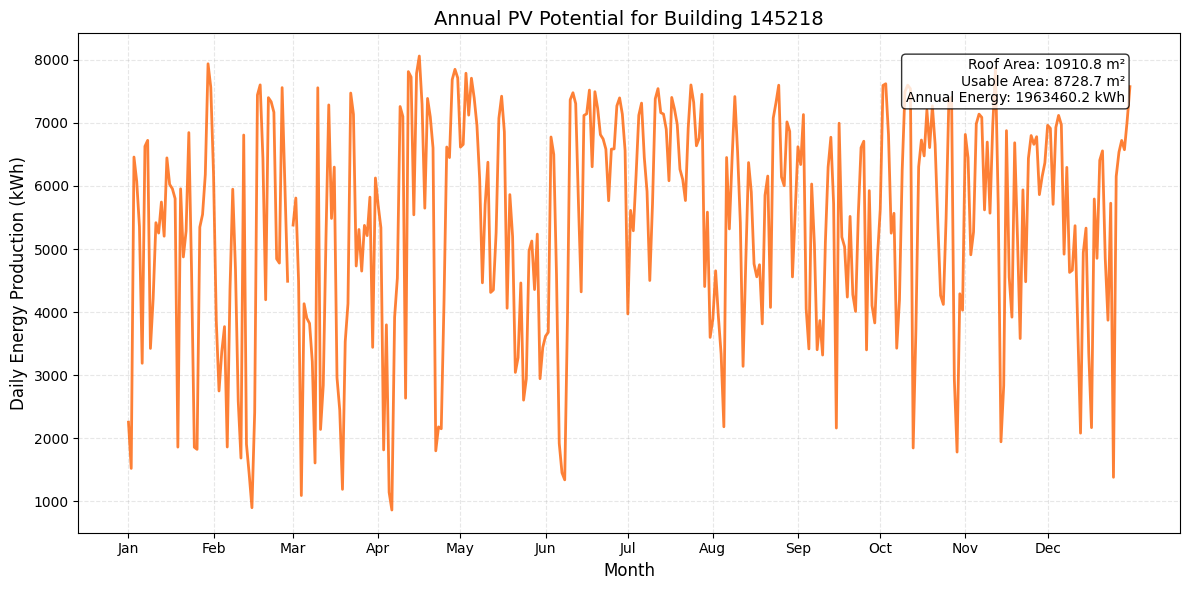

In [10]:
# Visualize the daily energy production of one building over the year.
# Here we pick the building with the largest annual production; you can use any value in the 'building_id' column
example_id = buildings.loc[buildings['annual_energy'].idxmax(), 'building_id']
visualize_building_annual_pv(buildings, example_id, pvout_result_fixed, module_area=module_area)
plt.show()